<a href="https://colab.research.google.com/github/irdinafishar-bit/Tourism-Forecasting-Gender-Trends-for-Malaysia-2025-2027-/blob/main/Tourism_Forecasting_%26_Gender_Trends_For_Malaysia_(2025_2027).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Exploring and Predicting Foreign Tourist Arrivals using Machine Learning**

Step 1: Choosing and Importing the Dataset

In [ ]:
# Mount Google Drive to access the dataset
from google.colab import drive
import pandas as pd

drive.mount('/content/drive')  # Connect to Google Drive

# Load the cleaned tourist arrivals dataset from Google Drive
data_frame = pd.read_csv('/content/drive/My Drive/cleanedarrivals2.csv')

# Convert 'month_year' column to datetime format
data_frame['month_year'] = pd.to_datetime(data_frame['month_year'], format='%b-%Y')

# Filter the dataset to include only data from 2022 to 2024
df_edited = data_frame[(data_frame['month_year'].dt.year >= 2022) & (data_frame['month_year'].dt.year <= 2024)]

# Display the filtered dataset
print(df_edited)

Mounted at /content/drive
      month_year country  arrivals  arrivals_male  arrivals_female
24    2022-01-01     ABW         0              0                0
25    2022-02-01     ABW         0              0                0
26    2022-03-01     ABW         0              0                0
27    2022-04-01     ABW         1              0                1
28    2022-05-01     ABW         0              0                0
...          ...     ...       ...            ...              ...
12929 2024-06-01     ZWE       181             91               90
12930 2024-07-01     ZWE       213             86              127
12931 2024-08-01     ZWE       205             88              117
12932 2024-09-01     ZWE       252            112              140
12933 2024-10-01     ZWE       220             97              123

[7582 rows x 5 columns]


# **Step 2: Making a Time-Series Model for Predicting the Total Number of Arrivals from 2025 to 2027 (Line Plot)**

XGBoost

Fitting 3 folds for each of 40 candidates, totalling 120 fits


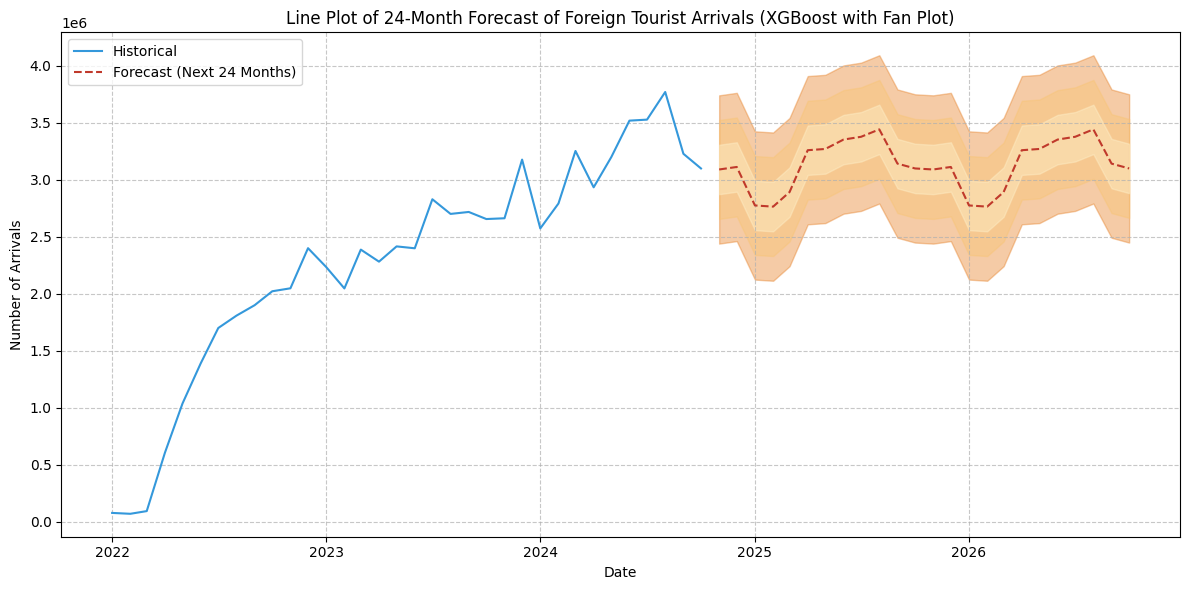

Best Parameters: {'subsample': 0.9, 'reg_lambda': 1, 'reg_alpha': 0, 'n_estimators': 300, 'min_child_weight': 1, 'max_depth': 5, 'learning_rate': 0.1, 'gamma': 0, 'colsample_bytree': 0.8}
Mean Absolute Error: 164569.875
Root Mean Squared Error: 195120.21451402723
R-squared: 0.7667582035064697


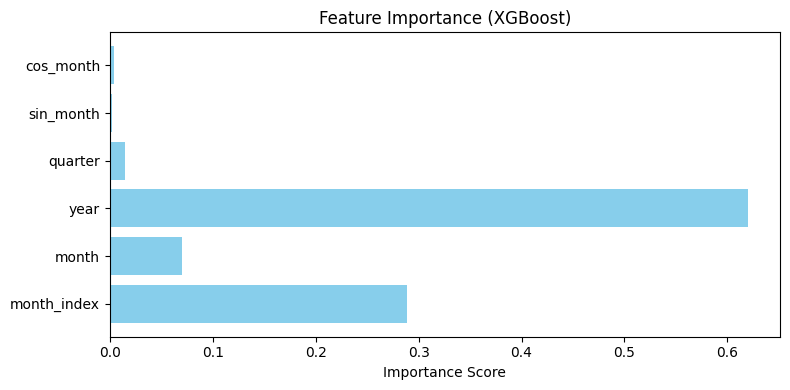

In [ ]:
# --- INSTALL REQUIRED LIBRARIES ---
!pip install scikit-learn    # Install scikit-learn for ML algorithms and tools
!pip install xgboost         # Install XGBoost for gradient boosting regression

# --- LIBRARY IMPORTS ---
import numpy as np                        # For numerical operations
import pandas as pd                       # For data manipulation
import matplotlib.pyplot as plt           # For data visualization
from xgboost import XGBRegressor          # XGBoost regression model
from sklearn.model_selection import train_test_split, RandomizedSearchCV  # For data splitting and tuning
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score  # For model evaluation

# --- DATA PREPROCESSING ---

df_edited = df_edited.copy()  # Create a copy to avoid changing the original dataset

df_edited['month_year'] = pd.to_datetime(df_edited['month_year'])  # Convert date column to datetime format

monthly_data = df_edited.groupby('month_year')['arrivals'].sum().reset_index()  # Aggregate total arrivals per month

monthly_data['month_index'] = np.arange(len(monthly_data))  # Create a continuous month index

# Extract time-based features for seasonality
monthly_data['month'] = monthly_data['month_year'].dt.month
monthly_data['year'] = monthly_data['month_year'].dt.year
monthly_data['quarter'] = monthly_data['month_year'].dt.quarter

# Encode month as cyclical features for seasonality pattern capture
monthly_data['sin_month'] = np.sin(2 * np.pi * monthly_data['month'] / 12)
monthly_data['cos_month'] = np.cos(2 * np.pi * monthly_data['month'] / 12)

# Select input features (X) and target variable (y)
X = monthly_data[['month_index', 'month', 'year', 'quarter', 'sin_month', 'cos_month']]
y = monthly_data['arrivals']

# --- TRAIN-TEST SPLIT ---
x_train, x_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)  # 80/20 split

# --- HYPERPARAMETER TUNING WITH RANDOMIZED SEARCH ---

# Define the range of hyperparameters to search
param_dist = {
    'n_estimators': [300, 500, 700, 1000],        # Number of boosting rounds
    'learning_rate': [0.01, 0.03, 0.05, 0.1],     # Step size shrinkage
    'max_depth': [4, 5, 6, 8],                    # Tree depth
    'subsample': [0.7, 0.8, 0.9],                 # Fraction of samples used per tree
    'colsample_bytree': [0.6, 0.8, 1.0],          # Fraction of features used per tree
    'gamma': [0, 1, 5],                           # Minimum loss reduction for a split
    'reg_alpha': [0, 0.5, 1],                     # L1 regularization
    'reg_lambda': [0.5, 1, 2],                    # L2 regularization
    'min_child_weight': [1, 3, 5]                 # Minimum sum of instance weights in a child
}

xgb_base = XGBRegressor(random_state=42)  # Initialize base XGBoost model

# Set up randomized search for best hyperparameters
xgb_search = RandomizedSearchCV(
    estimator=xgb_base,
    param_distributions=param_dist,
    n_iter=40,            # Try 40 combinations
    cv=3,                 # 3-fold cross-validation
    scoring='r2',         # Use R² score to evaluate
    verbose=1,            # Show progress
    random_state=42,      # Reproducibility
    n_jobs=-1             # Use all CPU cores
)

xgb_search.fit(x_train, y_train)              # Run the hyperparameter tuning
best_xgb = xgb_search.best_estimator_        # Retrieve the best model found

# --- PREDICT ON TEST SET ---
y_pred = best_xgb.predict(x_test)            # Make predictions on the test set

# --- FORECAST NEXT 24 MONTHS ---

# Generate list of next 24 months
last_month = monthly_data['month_year'].max()
future_dates = pd.date_range(start=last_month + pd.DateOffset(months=1), periods=24, freq='MS')

# Create future DataFrame
future_df = pd.DataFrame({'month_year': future_dates})
future_df['month_index'] = np.arange(monthly_data['month_index'].max() + 1, monthly_data['month_index'].max() + 25)
future_df['month'] = future_df['month_year'].dt.month
future_df['year'] = future_df['month_year'].dt.year
future_df['quarter'] = future_df['month_year'].dt.quarter
future_df['sin_month'] = np.sin(2 * np.pi * future_df['month'] / 12)
future_df['cos_month'] = np.cos(2 * np.pi * future_df['month'] / 12)

X_future = future_df[['month_index', 'month', 'year', 'quarter', 'sin_month', 'cos_month']]  # Features for prediction
y_future = best_xgb.predict(X_future)  # Forecast arrivals

# --- PLOT FORECAST WITH FAN BANDS ---

std_dev = np.std(y_future)  # Standard deviation for fan bands
levels = [1, 2, 3]          # Confidence intervals
colors = ['#FFF3CD', '#F8C471', '#E67E22']  # Shades for fan bands

plt.figure(figsize=(12, 6))  # Set plot size
plt.plot(monthly_data['month_year'], y, label='Historical', color='#3498DB')  # Plot historical data
plt.plot(future_df['month_year'], y_future, label='Forecast (Next 24 Months)', color='#C0392B', linestyle='--')  # Forecast line

# Add fan bands (±1σ, ±2σ, ±3σ)
for i, z in reversed(list(enumerate(levels))):
    upper = y_future + z * std_dev
    lower = y_future - z * std_dev
    plt.fill_between(future_df['month_year'], lower, upper, color=colors[i], alpha=0.4)

# Final plot formatting
plt.title('Line Plot of 24-Month Forecast of Foreign Tourist Arrivals (XGBoost with Fan Plot)')
plt.xlabel('Date')
plt.ylabel('Number of Arrivals')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

# --- EVALUATION METRICS ---

print("Best Parameters:", xgb_search.best_params_)  # Display best parameters found
mae = mean_absolute_error(y_test, y_pred)           # Calculate MAE
rmse = np.sqrt(mean_squared_error(y_test, y_pred))  # Calculate RMSE
r2 = r2_score(y_test, y_pred)                       # Calculate R² score

# Print evaluation results
print("Mean Absolute Error:", mae)
print("Root Mean Squared Error:", rmse)
print("R-squared:", r2)

# --- FEATURE IMPORTANCE ---

importances_xgb = best_xgb.feature_importances_  # Get feature importance scores
features_xgb = X.columns                         # Get feature names

# Plot feature importances
plt.figure(figsize=(8, 4))
plt.barh(features_xgb, importances_xgb, color='skyblue')
plt.title('Feature Importance (XGBoost)')
plt.xlabel('Importance Score')
plt.tight_layout()
plt.show()

Random Forest

Fitting 3 folds for each of 30 candidates, totalling 90 fits


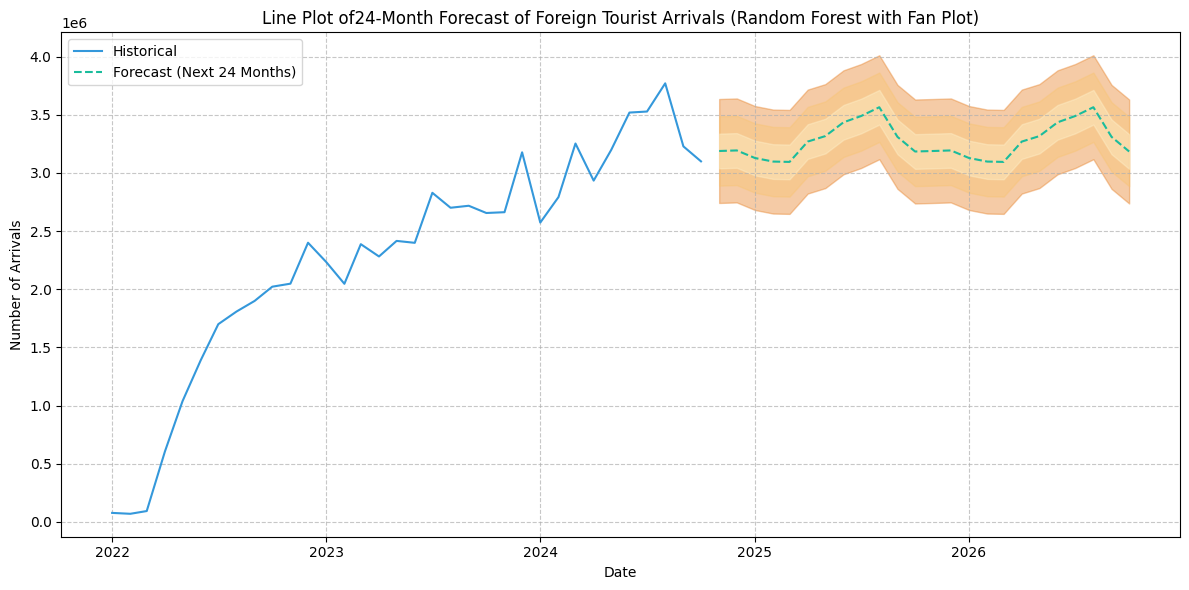

Random Forest Mean Absolute Error:  166805.41190476195
Random Forest Root Mean Squared Error:  203567.5678977193
Random Forest R-squared:  0.7461255226128767


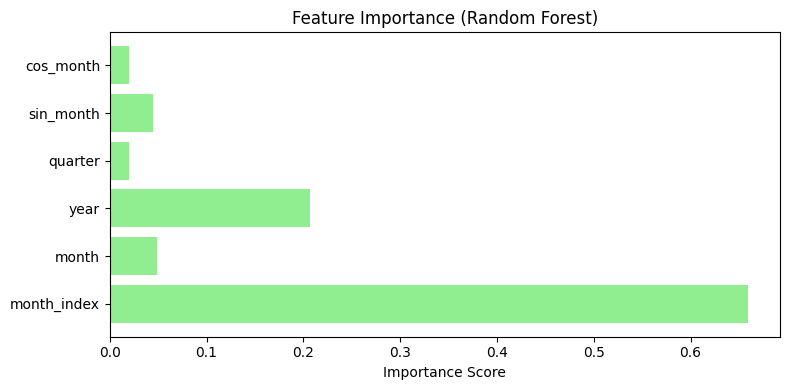

In [ ]:
# --- RANDOM FOREST REGRESSION WITH FEATURED INPUTS ---
from sklearn.metrics import mean_squared_error
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import RandomizedSearchCV

# --- DATA PREPROCESSING ---

# Make a safe copy of the dataset to avoid modifying the original
df_edited = df_edited.copy()

# Convert 'month_year' column to datetime format
df_edited['month_year'] = pd.to_datetime(df_edited['month_year'])

# Aggregate total arrivals by month
monthly_data = df_edited.groupby('month_year')['arrivals'].sum().reset_index()

# Create a continuous time index (month_index) starting from 0
monthly_data['month_index'] = np.arange(len(monthly_data))

# Extract additional time-related features
monthly_data['month'] = monthly_data['month_year'].dt.month      # Month number (1–12)
monthly_data['year'] = monthly_data['month_year'].dt.year        # Year value
monthly_data['quarter'] = monthly_data['month_year'].dt.quarter  # Quarter (1–4)

# Encode month as cyclical features using sine and cosine
monthly_data['sin_month'] = np.sin(2 * np.pi * monthly_data['month'] / 12)
monthly_data['cos_month'] = np.cos(2 * np.pi * monthly_data['month'] / 12)

# Define features (X) and target variable (y)
X = monthly_data[['month_index', 'month', 'year', 'quarter', 'sin_month', 'cos_month']]
y = monthly_data['arrivals']

# Reuse the same X and y as used in XGBoost
x_train, x_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

from sklearn.model_selection import RandomizedSearchCV

# Initialize base model
rf_base = RandomForestRegressor(random_state=42)

# Define the parameter distribution for RandomizedSearchCV
param_dist = {
    'n_estimators': [300, 500, 800, 1000],
    'max_depth': [6, 10, 15, 20],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4, 8],
    'max_features': ['sqrt', 'log2', 0.8],
    'bootstrap': [True, False]
}

# Set up randomized search
random_search = RandomizedSearchCV(
    estimator=rf_base,
    param_distributions=param_dist,
    n_iter=30,
    cv=3,
    scoring='r2',
    verbose=1,
    random_state=42,
    n_jobs=-1
)

# Run the search on training data
random_search.fit(x_train, y_train)

# Use the best model from search
model_rf = random_search.best_estimator_

# Prepare future data for forecasting (same as in XGBoost)
X_future_rf = future_df[['month_index', 'month', 'year', 'quarter', 'sin_month', 'cos_month']]

# Forecast next 24 months using Random Forest
y_future_rf = model_rf.predict(X_future_rf)

# --- Forecast Plot with Fan Bands Overlayed ---

plt.figure(figsize=(12, 6))

# Plot historical data
plt.plot(monthly_data['month_year'], y, label='Historical', color='#3498DB')

# Plot forecast line for the next 24 months
plt.plot(future_df['month_year'], y_future_rf, label='Forecast (Next 24 Months)', color='#1ABC9C', linestyle='--')

# Calculate forecast uncertainty (fan band std deviation)
std_deviation_rf = np.std(y_future_rf)

# Define fan levels and distinguishable colors
levels = [1, 2, 3]
colors = ['#FFF3CD', '#F8C471', '#E67E22'] # Light to darker green shades

# Add fan bands (confidence intervals)
for i, z in reversed(list(enumerate(levels))):
    upper = y_future_rf + z * std_deviation_rf
    lower = y_future_rf - z * std_deviation_rf
    plt.fill_between(future_df['month_year'], lower, upper, color=colors[i], alpha=0.4)

# Final formatting
plt.title('Line Plot of24-Month Forecast of Foreign Tourist Arrivals (Random Forest with Fan Plot)')
plt.xlabel('Date')
plt.ylabel('Number of Arrivals')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

# --- Evaluate on historical test set ---
y_pred_historical_rf = model_rf.predict(x_test)

mae_rf = mean_absolute_error(y_test, y_pred_historical_rf)
rmse_rf = np.sqrt(mean_squared_error(y_test, y_pred_historical_rf))
r2_rf = r2_score(y_test, y_pred_historical_rf)

print("Random Forest Mean Absolute Error: ", mae_rf)
print("Random Forest Root Mean Squared Error: ", rmse_rf)
print("Random Forest R-squared: ", r2_rf)

# --- Feature Importance ---
importances_rf = model_rf.feature_importances_
features_rf = X.columns

plt.figure(figsize=(8, 4))
plt.barh(features_rf, importances_rf, color='lightgreen')
plt.title('Feature Importance (Random Forest)')
plt.xlabel('Importance Score')
plt.tight_layout()
plt.show()



**Step 3: Making A Time Series Forecasting Model (Line Plots) for Predicting the Top 10 Countries with Most Tourist Arrivals from 2025 to 2027**

In [ ]:
# Group the dataset by both 'country' and 'month_year', then sum up arrivals per group
df_country_monthly = df_edited.groupby(['country', 'month_year'])['arrivals'].sum().reset_index()

# Display the first few rows to verify the grouped structure
display(df_country_monthly.head())

,country,month_year,arrivals
0,ABW,2022-01-01,0
1,ABW,2022-02-01,0
2,ABW,2022-03-01,0
3,ABW,2022-04-01,1
4,ABW,2022-05-01,0


In [ ]:
# Group by country to get total arrivals per country across the entire period
country_total_arrivals = df_country_monthly.groupby('country')['arrivals'].sum().reset_index()

# Sort countries in descending order of total arrivals
country_total_arrivals_sorted = country_total_arrivals.sort_values(by='arrivals', ascending=False)

# Select the top 10 countries with the highest tourist arrivals
top_n = 10
top_countries_df = country_total_arrivals_sorted.head(top_n)

# Extract the list of country names for later use in modeling
top_countries_list = top_countries_df['country'].tolist()

# Print and display the results
print(f"Top {top_n} countries by total arrivals (2022-2024):")
display(top_countries_df)
print("\nList of top countries:")
print(top_countries_list)

Top 10 countries by total arrivals (2022-2024):


,country,arrivals
173,SGP,38324572
91,IDN,9073798
195,THA,5538675
39,CHN,5167059
30,BRN,2947346
92,IND,2617022
156,PHL,1251024
19,BGD,1208700
109,KOR,1110392
215,VNM,946067



List of top countries:
['SGP', 'IDN', 'THA', 'CHN', 'BRN', 'IND', 'PHL', 'BGD', 'KOR', 'VNM']


Training using Random Forest for Top 10 Countries

In [ ]:
from sklearn.ensemble import RandomForestRegressor
import pandas as pd
import numpy as np

# Create a dictionary to store trained Random Forest models for each country
country_models = {}

# Make a copy of the monthly dataset to avoid unintended modification
df_country_monthly = df_country_monthly.copy()

# Extract year and month as separate features for time-based modeling
df_country_monthly['year'] = df_country_monthly['month_year'].dt.year
df_country_monthly['month'] = df_country_monthly['month_year'].dt.month

# Create a continuous index for months (useful for regression models)
df_country_monthly['month_index'] = (df_country_monthly['year'] - df_country_monthly['year'].min()) * 12 + \
                                     df_country_monthly['month'] - df_country_monthly['month'].min()

# Filter only the data for the training range: 2022 to 2024
df_train_period = df_country_monthly[(df_country_monthly['year'] >= 2022) &
                                     (df_country_monthly['year'] <= 2024)].copy()

# Loop through each top country to train a separate model
for country in top_countries_list:
    print(f"Training model for {country}...")

    # Filter the dataset to include only rows for the current country
    country_data = df_train_period[df_train_period['country'] == country].copy()

    # Sort the country-specific data chronologically
    country_data = country_data.sort_values(by='month_year')

    # Add derived features to country_data before training
    country_data['month'] = country_data['month_year'].dt.month
    country_data['year'] = country_data['month_year'].dt.year
    country_data['quarter'] = country_data['month_year'].dt.quarter
    country_data['month_index'] = (country_data['year'] - country_data['year'].min()) * 12 + \
                                  (country_data['month'] - country_data['month'].min())
    country_data['sin_month'] = np.sin(2 * np.pi * country_data['month'] / 12)
    country_data['cos_month'] = np.cos(2 * np.pi * country_data['month'] / 12)

    # Define feature set (X) and target (y)
    X_train_country = country_data[['month_index', 'year', 'month', 'quarter', 'sin_month', 'cos_month']]
    y_train_country = country_data['arrivals']

    # Only train if there is data available
    if not X_train_country.empty:
        # Train a Random Forest model with 1000 trees and max depth of 5
        model = RandomForestRegressor(n_estimators=1000, max_depth=5, random_state=42)
        model.fit(X_train_country, y_train_country)

        # Save the trained model into the dictionary
        country_models[country] = model
        print(f"Model trained for {country}.")
    else:
        print(f"Not enough data to train a model for {country}.")

print("\nTraining complete for all top countries.")

Training model for SGP...
Model trained for SGP.
Training model for IDN...
Model trained for IDN.
Training model for THA...
Model trained for THA.
Training model for CHN...
Model trained for CHN.
Training model for BRN...
Model trained for BRN.
Training model for IND...
Model trained for IND.
Training model for PHL...
Model trained for PHL.
Training model for BGD...
Model trained for BGD.
Training model for KOR...
Model trained for KOR.
Training model for VNM...
Model trained for VNM.

Training complete for all top countries.


In [ ]:
import pandas as pd
import numpy as np

# Dictionary to store predicted results per country
country_predictions = {}

# Generate a date range from January 2025 to December 2027
start_date_pred = pd.to_datetime('2025-01-01')
end_date_pred = pd.to_datetime('2027-12-01')
prediction_dates = pd.date_range(start=start_date_pred, end=end_date_pred, freq='MS')

# Create a DataFrame to hold future dates
df_predict_period = pd.DataFrame({'month_year': prediction_dates})

# Extract time-based features
df_predict_period['year'] = df_predict_period['month_year'].dt.year
df_predict_period['month'] = df_predict_period['month_year'].dt.month
df_predict_period['quarter'] = df_predict_period['month_year'].dt.quarter

# Compute 'month_index' relative to the training start (assumed 2022-01)
first_year_train = df_country_monthly['year'].min()
first_month_train = df_country_monthly['month'].min()
df_predict_period['month_index'] = (df_predict_period['year'] - first_year_train) * 12 + \
                                   (df_predict_period['month'] - first_month_train)

# Add cyclical encoding
df_predict_period['sin_month'] = np.sin(2 * np.pi * df_predict_period['month'] / 12)
df_predict_period['cos_month'] = np.cos(2 * np.pi * df_predict_period['month'] / 12)

# Forecast for each top country using their trained model
for country, model in country_models.items():
    print(f"Predicting arrivals for {country} (2025-2027)...")

    # Match training features exactly
    X_predict_country = df_predict_period[['month_index', 'year', 'month', 'quarter', 'sin_month', 'cos_month']]

    # Predict
    predicted_arrivals = model.predict(X_predict_country)

    # Store results (ensure non-negative and rounded)
    country_predictions[country] = df_predict_period.copy()
    country_predictions[country]['predicted_arrivals'] = np.maximum(predicted_arrivals, 0).round().astype(int)

print("\nPredictions complete for all top countries.")

# Preview results
if country_predictions:
    example_country = list(country_predictions.keys())[0]
    print(f"\nExample predictions for {example_country}:")
    display(country_predictions[example_country].head())

Predicting arrivals for SGP (2025-2027)...
Predicting arrivals for IDN (2025-2027)...
Predicting arrivals for THA (2025-2027)...
Predicting arrivals for CHN (2025-2027)...
Predicting arrivals for BRN (2025-2027)...
Predicting arrivals for IND (2025-2027)...
Predicting arrivals for PHL (2025-2027)...
Predicting arrivals for BGD (2025-2027)...
Predicting arrivals for KOR (2025-2027)...
Predicting arrivals for VNM (2025-2027)...

Predictions complete for all top countries.

Example predictions for SGP:


,month_year,year,month,quarter,month_index,sin_month,cos_month,predicted_arrivals
0,2025-01-01,2025,1,1,36,0.500000,8.660254e-01,1551746
1,2025-02-01,2025,2,1,37,0.866025,5.000000e-01,1556381
2,2025-03-01,2025,3,1,38,1.000000,6.123234e-17,1604814
3,2025-04-01,2025,4,2,39,0.866025,-5.000000e-01,1589967
4,2025-05-01,2025,5,2,40,0.500000,-8.660254e-01,1606386



Calculate the total predicted arrivals for each country over the 2025-2027 period and identify the country with the highest total predicted arrivals to determine the most contributing country.



In [ ]:
import pandas as pd

# Create a dictionary to store the sum of predicted arrivals for each country
country_total_predicted_arrivals = {}
for country, predictions_df in country_predictions.items():
    total_predicted = predictions_df['predicted_arrivals'].sum()  # Sum predicted values
    country_total_predicted_arrivals[country] = total_predicted   # Store in dictionary

# Convert the dictionary to a DataFrame for easier viewing
total_predicted_arrivals_df = pd.DataFrame.from_dict(
    country_total_predicted_arrivals, orient='index', columns=['total_predicted_arrivals'])

# Sort countries by predicted arrivals in descending order
total_predicted_arrivals_df_sorted = total_predicted_arrivals_df.sort_values(by='total_predicted_arrivals', ascending=False)

# Identify the top contributing country and its arrival count
most_contributing_country = total_predicted_arrivals_df_sorted.index[0]
highest_predicted_arrivals = total_predicted_arrivals_df_sorted.iloc[0]['total_predicted_arrivals']

# Display the sorted table and print the top contributor
print("Total Predicted Tourist Arrivals for Top Countries (2025-2027):")
display(total_predicted_arrivals_df_sorted)

print(f"\nBased on the predictions, the most contributing country to Malaysia's tourism from 2025 to 2027 is likely: {most_contributing_country} with a total of {highest_predicted_arrivals:,} predicted arrivals.")

Total Predicted Tourist Arrivals for Top Countries (2025-2027):


,total_predicted_arrivals
SGP,58287753
IDN,12891525
CHN,12513021
THA,6998700
BRN,4614459
IND,4531407
PHL,1865058
KOR,1754208
VNM,1212171
BGD,1072479



Based on the predictions, the most contributing country to Malaysia's tourism from 2025 to 2027 is likely: SGP with a total of 58,287,753 predicted arrivals.


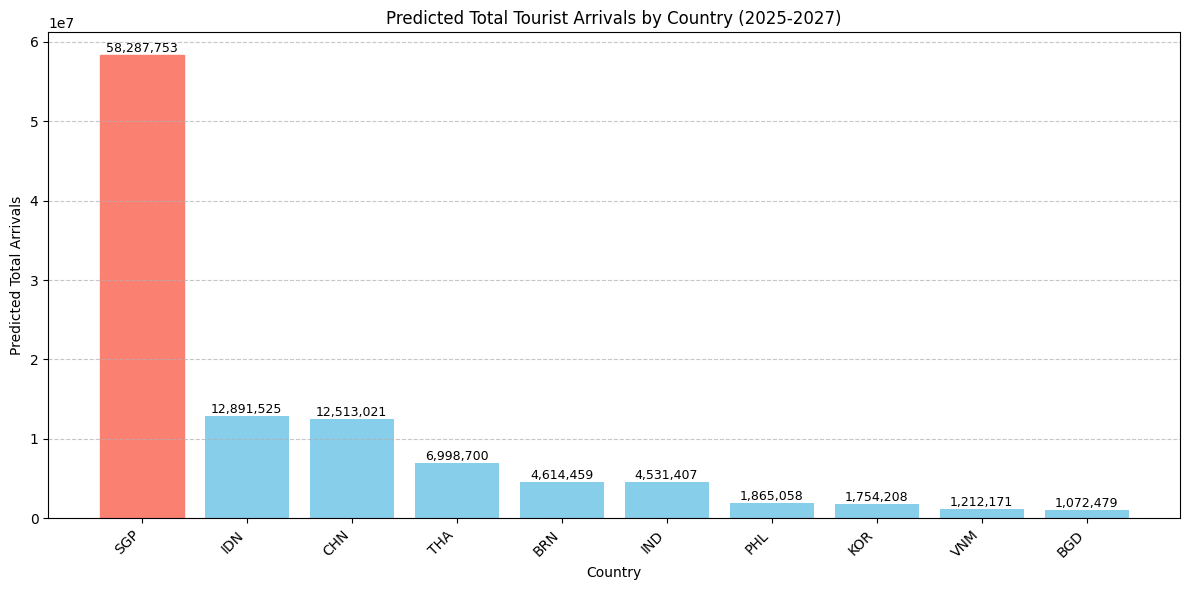

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Create a bar chart to show predicted arrivals by country
plt.figure(figsize=(12, 6))  # Set the figure size
bars = plt.bar(
    total_predicted_arrivals_df_sorted.index,  # x-axis: country names
    total_predicted_arrivals_df_sorted['total_predicted_arrivals'],  # y-axis: total predicted arrivals
    color='skyblue'  # Initial bar color
)

# Highlight the country with the highest predicted arrivals
most_contributing_country = total_predicted_arrivals_df_sorted.index[0]
most_contributing_bar_index = total_predicted_arrivals_df_sorted.index.get_loc(most_contributing_country)
bars[most_contributing_bar_index].set_color('salmon')  # Change top country bar color

# Add titles and axis labels
plt.title('Predicted Total Tourist Arrivals by Country (2025-2027)')
plt.xlabel('Country')
plt.ylabel('Predicted Total Arrivals')
plt.xticks(rotation=45, ha='right')  # Rotate x-axis labels for readability
plt.grid(axis='y', linestyle='--', alpha=0.7)  # Add horizontal grid lines

# Add value labels on top of each bar
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, yval, f'{yval:,.0f}', va='bottom', ha='center', fontsize=9)

plt.tight_layout()  # Adjust layout to avoid label overlap
plt.show()  # Display the plot

In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

# Initialize a dictionary to store evaluation metrics for each country
country_evaluation_metrics = {}

print("Evaluating models for top countries...")

# Loop through each top country to evaluate model performance
for country in top_countries_list:
    print(f"\nEvaluating model for {country}...")

    # Extract historical data for the current country
    country_data = df_country_monthly[df_country_monthly['country'] == country].copy()
    country_data = country_data.sort_values(by='month_year')  # Ensure chronological order
    country_data['quarter'] = country_data['month_year'].dt.quarter
    country_data['sin_month'] = np.sin(2 * np.pi * country_data['month'] / 12)
    country_data['cos_month'] = np.cos(2 * np.pi * country_data['month'] / 12)

    # Define input features and target variable
    X_country = country_data[['month_index', 'year', 'month', 'quarter', 'sin_month', 'cos_month']]
    y_country = country_data['arrivals']

    # Time-aware 80/20 train-test split (no shuffling)
    train_size = int(len(country_data) * 0.8)
    X_train_country, X_test_country = X_country[:train_size], X_country[train_size:]
    y_train_country, y_test_country = y_country[:train_size], y_country[train_size:]

    # Only evaluate if both train and test sets have data
    if not X_train_country.empty and not X_test_country.empty:
        model = country_models[country]  # Get the trained model
        y_pred_country = model.predict(X_test_country)  # Predict on test data
        y_pred_country[y_pred_country < 0] = 0  # Ensure non-negative predictions

        # Compute evaluation metrics
        mae = mean_absolute_error(y_test_country, y_pred_country)
        rmse = np.sqrt(mean_squared_error(y_test_country, y_pred_country))
        r2 = r2_score(y_test_country, y_pred_country)

        # Store metrics in the dictionary
        country_evaluation_metrics[country] = {
            'MAE': mae,
            'RMSE': rmse,
            'R-squared': r2
        }

        # Print the metrics for review
        print(f"  MAE: {mae:.2f}")
        print(f"  RMSE: {rmse:.2f}")
        print(f"  R-squared: {r2:.4f}")
    else:
        print(f"  Not enough data for {country} to create both training and testing sets with the 80/20 split.")

print("\nEvaluation complete for all top countries.")

# Convert the metrics dictionary to a DataFrame for better display
evaluation_df = pd.DataFrame.from_dict(country_evaluation_metrics, orient='index')
print("\nSummary of Evaluation Metrics:")
display(evaluation_df)

Evaluating models for top countries...

Evaluating model for SGP...
  MAE: 49965.20
  RMSE: 60537.29
  R-squared: 0.7997

Evaluating model for IDN...
  MAE: 5796.52
  RMSE: 8108.02
  R-squared: 0.8553

Evaluating model for THA...
  MAE: 4969.41
  RMSE: 5546.70
  R-squared: 0.6322

Evaluating model for CHN...
  MAE: 25900.33
  RMSE: 30299.59
  R-squared: 0.8905

Evaluating model for BRN...
  MAE: 9250.71
  RMSE: 11254.68
  R-squared: 0.8063

Evaluating model for IND...
  MAE: 6600.79
  RMSE: 8638.08
  R-squared: 0.7791

Evaluating model for PHL...
  MAE: 2799.85
  RMSE: 3159.49
  R-squared: 0.7348

Evaluating model for BGD...
  MAE: 5152.78
  RMSE: 7224.25
  R-squared: 0.7359

Evaluating model for KOR...
  MAE: 3845.33
  RMSE: 4060.14
  R-squared: 0.8326

Evaluating model for VNM...
  MAE: 2117.18
  RMSE: 2308.47
  R-squared: 0.8955

Evaluation complete for all top countries.

Summary of Evaluation Metrics:


,MAE,RMSE,R-squared
SGP,49965.196916,60537.294209,0.799714
IDN,5796.515256,8108.024619,0.855272
THA,4969.412931,5546.701028,0.632150
CHN,25900.328920,30299.590042,0.890547
BRN,9250.706290,11254.680053,0.806324
IND,6600.792613,8638.079121,0.779089
PHL,2799.847913,3159.493806,0.734767
BGD,5152.784782,7224.249755,0.735881
KOR,3845.330371,4060.142511,0.832559
VNM,2117.180316,2308.469788,0.895503


Time Series Forecasting Model (Line Plots) for the Top 10 Countries Predicted to have the Most Tourist Arrivals from 2025 to 2027

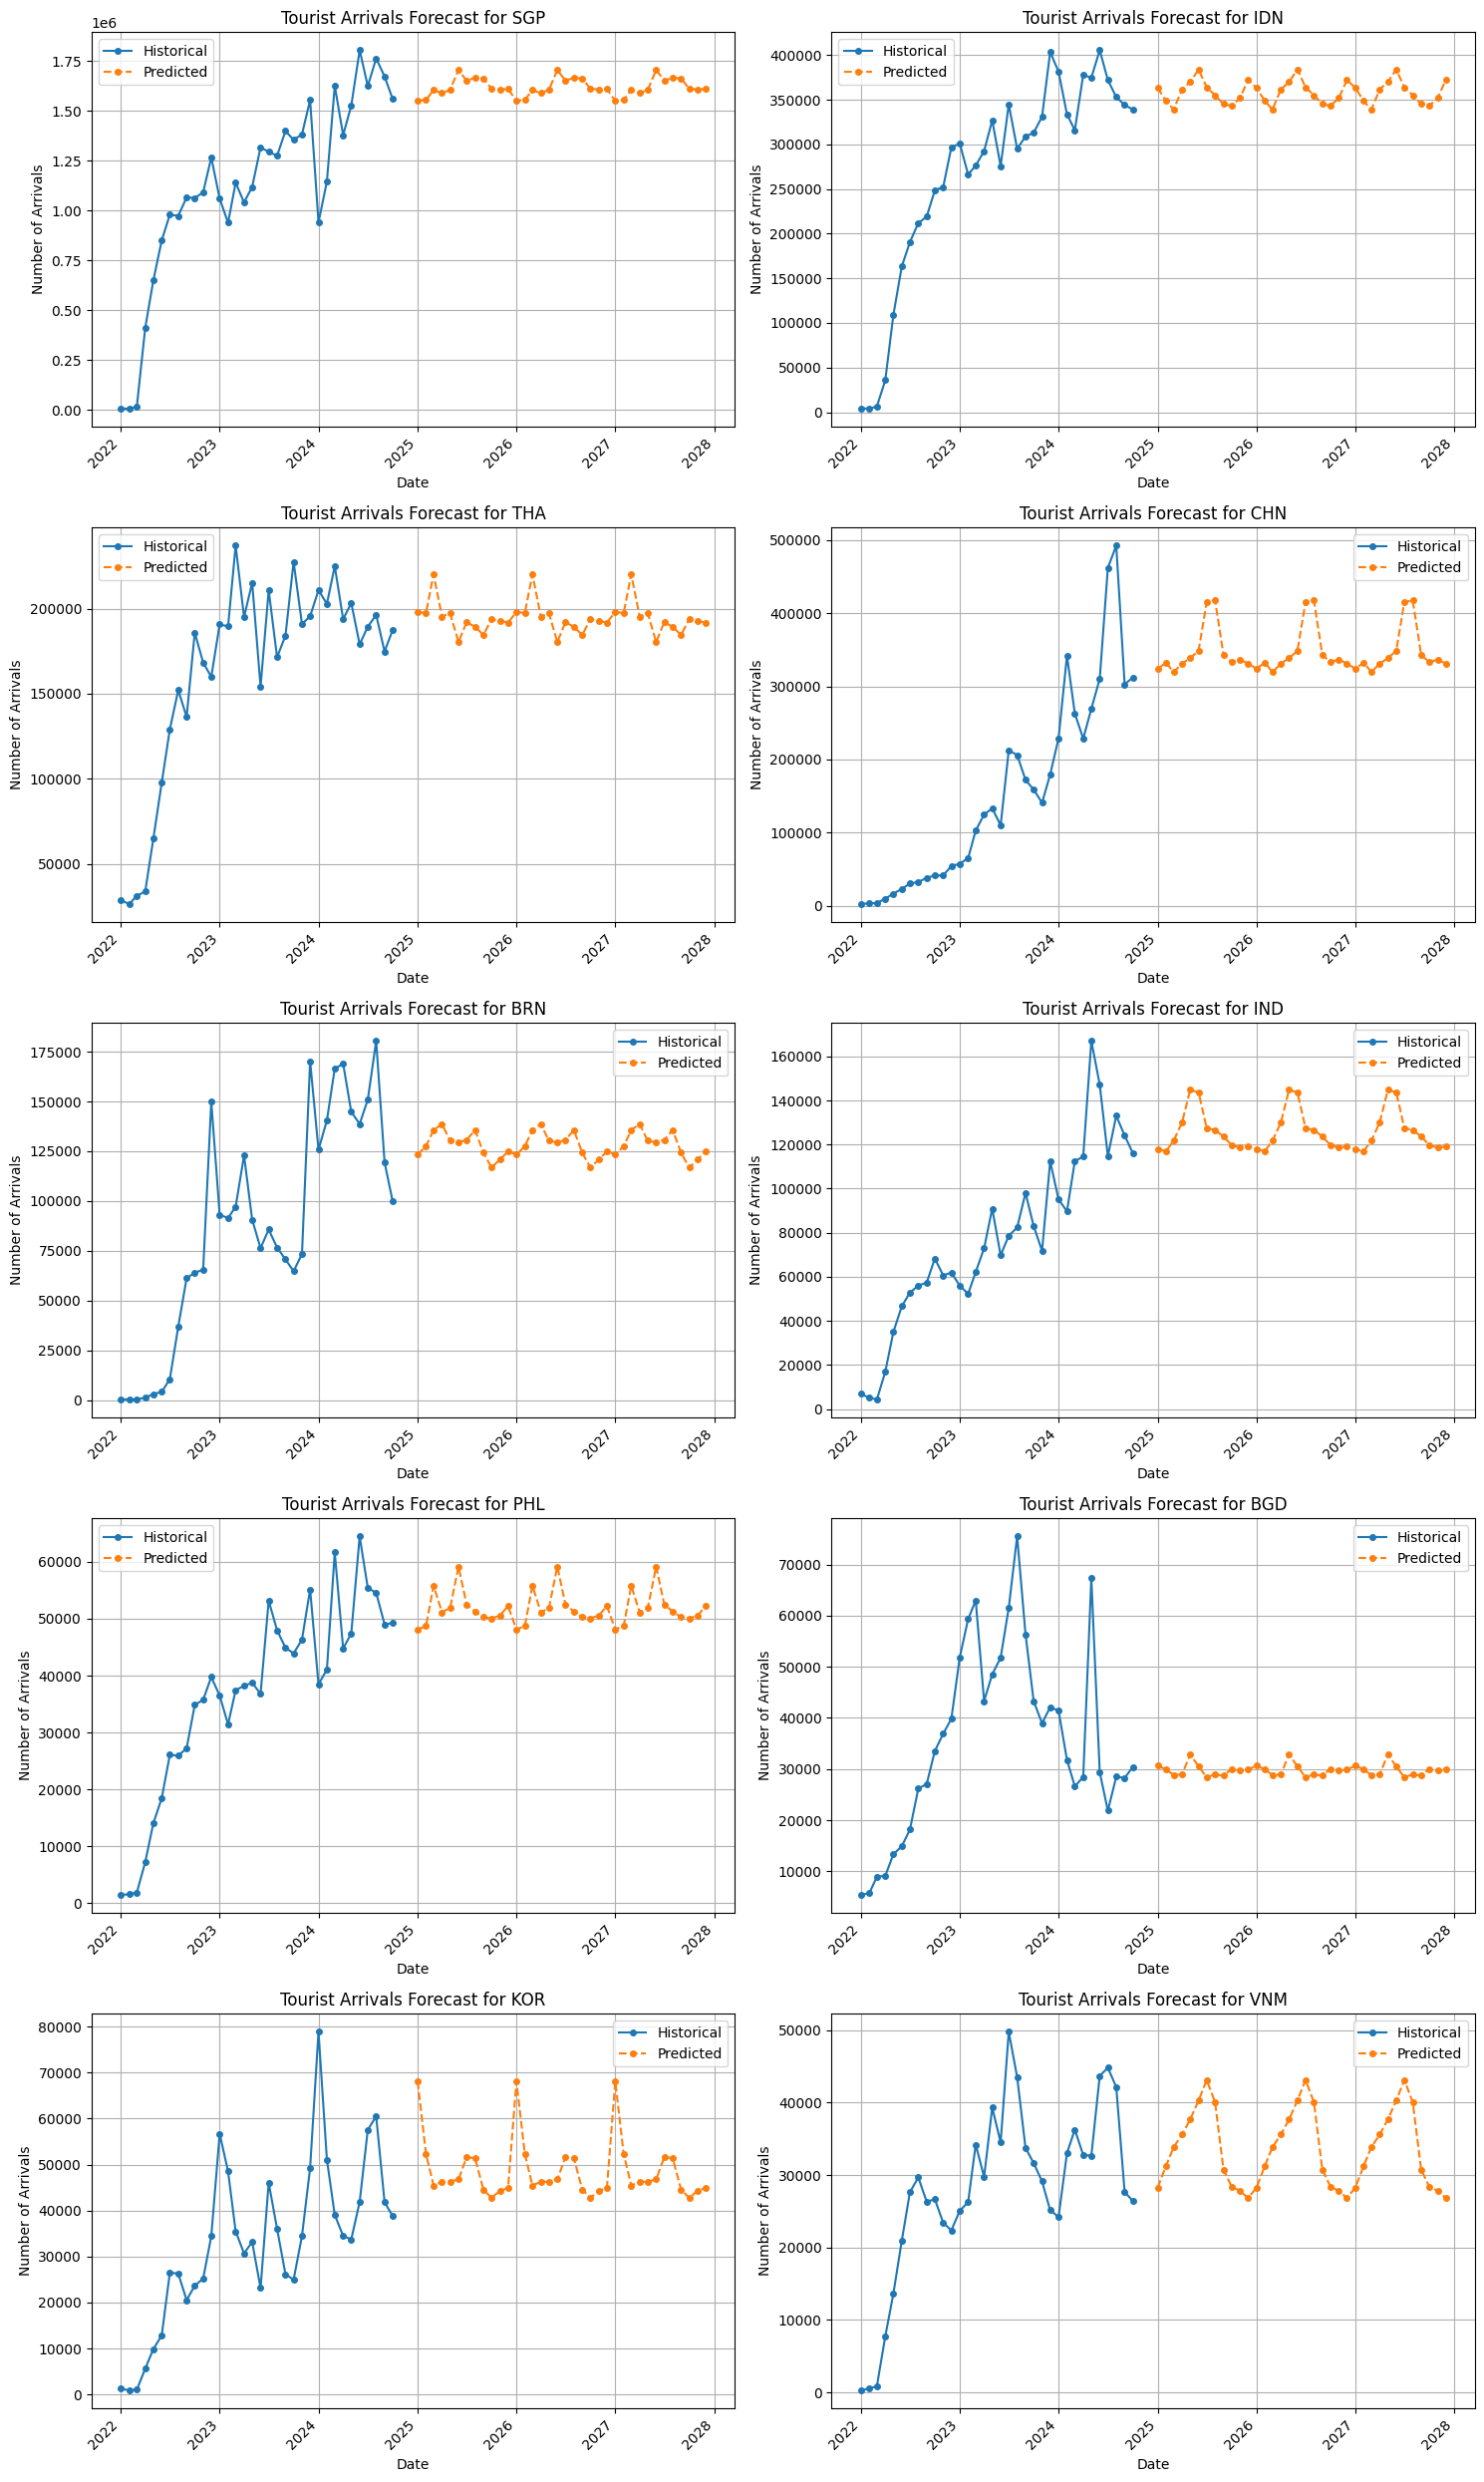

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

# Assuming df_country_monthly contains historical data with 'month_year', 'country', 'arrivals'
# Assuming country_predictions is a dictionary with country names as keys and DataFrames of predictions as values

# Get the list of top 10 countries (assuming top_countries_list is available)
# top_countries_list = total_predicted_arrivals_df_sorted.index[:10].tolist() # Ensure this list is correctly obtained

# Determine the number of rows and columns for the subplots
n_countries = len(top_countries_list)
n_cols = 2  # Number of columns in the subplot grid
n_rows = (n_countries + n_cols - 1) // n_cols # Calculate the number of rows needed


plt.figure(figsize=(15, n_rows * 5)) # Adjust figure size based on number of rows

for i, country in enumerate(top_countries_list):
    plt.subplot(n_rows, n_cols, i + 1) # Create a subplot for each country

    # Get historical data for the current country
    historical_data = df_country_monthly[df_country_monthly['country'] == country].copy()
    historical_data = historical_data.sort_values(by='month_year')

    # Get predicted data for the current country
    predicted_data = country_predictions[country].copy()

    # Plot historical data
    plt.plot(historical_data['month_year'], historical_data['arrivals'], label='Historical', marker='o', markersize=4)

    # Plot predicted data
    plt.plot(predicted_data['month_year'], predicted_data['predicted_arrivals'], label='Predicted', marker='o', markersize=4, linestyle='--')

    plt.title(f'Tourist Arrivals Forecast for {country}')
    plt.xlabel('Date')
    plt.ylabel('Number of Arrivals')
    plt.legend()
    plt.grid(True)
    plt.xticks(rotation=45, ha='right') # Rotate x-axis labels for better readability

plt.tight_layout() # Adjust layout to prevent overlapping titles and labels
plt.show()


**Step 4: Making A Gradient Boosting Model for Predicting the Most Dominant Gender of Tourists**

LightGBM - Binary Classification Confusion Matrix Heatmap for Predicting the Dominant Gender

[LightGBM] [Info] Number of positive: 3346, number of negative: 986
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000266 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 510
[LightGBM] [Info] Number of data points in the train set: 4332, number of used features: 2
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.772392 -> initscore=1.221865
[LightGBM] [Info] Start training from score 1.221865
Binary Classification Accuracy: 0.9779
Binary Classification Precision: 0.9807
Binary Classification Recall: 0.9909
Binary Classification F1-Score: 0.9858

Binary Classification Confusion Matrix:
 [[ 395   28]
 [  13 1421]]


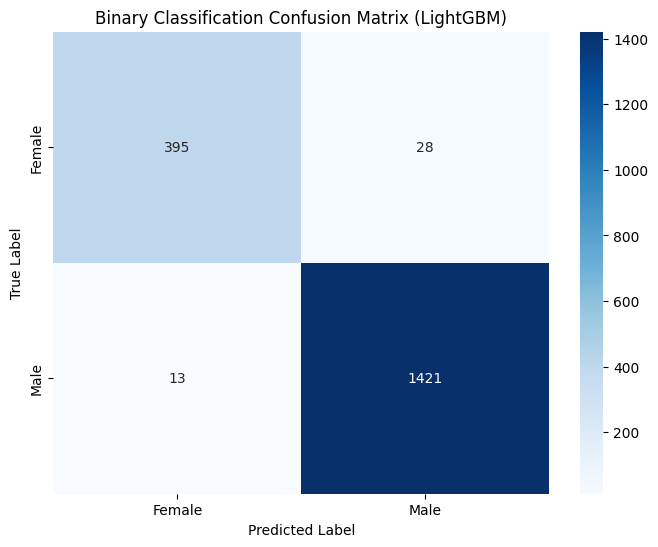

In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
import lightgbm as lgb
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# Determine dominant gender per row based on arrivals
df_edited['dominant_gender'] = df_edited.apply(
    lambda row: 'Male' if row['arrivals_male'] > row['arrivals_female']
    else ('Female' if row['arrivals_female'] > row['arrivals_male'] else 'Equal'),
    axis=1
)

# Filter out rows with 'Equal' for binary classification
df_binary = df_edited[df_edited['dominant_gender'] != 'Equal'].copy()

# Encode 'Male' as 1, 'Female' as 0
df_binary['dominant_gender_binary'] = df_binary['dominant_gender'].apply(lambda x: 1 if x == 'Male' else 0)

# Select features and target
X_binary = df_binary[['arrivals_male', 'arrivals_female']]  # Features
y_binary = df_binary['dominant_gender_binary']              # Target

# Split data (70% train, 30% test), with stratified sampling to preserve class balance
X_train_binary, X_test_binary, y_train_binary, y_test_binary = train_test_split(
    X_binary, y_binary, test_size=0.3, random_state=42, stratify=y_binary
)

# Initialize and train LightGBM classifier
lgb_clf = lgb.LGBMClassifier(random_state=42)
lgb_clf.fit(X_train_binary, y_train_binary)

# Predict on test set
y_pred_binary = lgb_clf.predict(X_test_binary)

# Evaluate classification performance
accuracy_binary = accuracy_score(y_test_binary, y_pred_binary)
precision_binary = precision_score(y_test_binary, y_pred_binary)
recall_binary = recall_score(y_test_binary, y_pred_binary)
f1_binary = f1_score(y_test_binary, y_pred_binary)
cm_binary = confusion_matrix(y_test_binary, y_pred_binary)

# Print evaluation metrics
print(f"Binary Classification Accuracy: {accuracy_binary:.4f}")
print(f"Binary Classification Precision: {precision_binary:.4f}")
print(f"Binary Classification Recall: {recall_binary:.4f}")
print(f"Binary Classification F1-Score: {f1_binary:.4f}")
print("\nBinary Classification Confusion Matrix:\n", cm_binary)

# Plot the confusion matrix
plt.figure(figsize=(8, 6))
sns.heatmap(cm_binary, annot=True, fmt='d', cmap='Blues', xticklabels=['Female', 'Male'], yticklabels=['Female', 'Male'])
plt.title('Binary Classification Confusion Matrix (LightGBM)')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()

In [ ]:
import pandas as pd
import numpy as np
from sklearn.linear_model import LinearRegression

# Create prediction dates for 2025–2027
start_date_pred = pd.to_datetime('2025-01-01')
end_date_pred = pd.to_datetime('2027-12-01')
prediction_dates = pd.date_range(start=start_date_pred, end=end_date_pred, freq='MS')
df_predict_binary = pd.DataFrame({'month_year': prediction_dates})

# Compute 'time_index' relative to the original dataset
first_year_train = df_edited['month_year'].dt.year.min()
first_month_train = df_edited['month_year'].dt.month.min()
df_predict_binary['time_index'] = (df_predict_binary['month_year'].dt.year - first_year_train) * 12 + \
                                  (df_predict_binary['month_year'].dt.month - first_month_train)

# Estimate historical male/female ratio
average_male_ratio = df_binary['arrivals_male'].sum() / (df_binary['arrivals_male'].sum() + df_binary['arrivals_female'].sum())
average_female_ratio = 1 - average_male_ratio

# Prepare total arrivals per month from past data
df_edited2_total_monthly = df_edited.groupby('month_year')['arrivals'].sum().reset_index().sort_values(by='month_year')

# Proceed only if at least 12 months of recent data are available
if len(df_edited2_total_monthly) >= 12:
    recent_data = df_edited2_total_monthly.tail(12).copy()
    recent_data['time_index_recent'] = np.arange(len(recent_data))  # Linear index

    # Fit a linear regression model to recent data
    linear_model = LinearRegression()
    linear_model.fit(recent_data[['time_index_recent']], recent_data['arrivals'])

    # Generate future time index for extrapolation
    start_index_pred = recent_data['time_index_recent'].max() + 1
    df_predict_binary['time_index_linear'] = np.arange(start_index_pred, start_index_pred + len(df_predict_binary))

    # Rename column to match model input
    X_predict_linear = df_predict_binary[['time_index_linear']].rename(columns={'time_index_linear': 'time_index_recent'})

    # Predict total arrivals using the linear model
    df_predict_binary['predicted_total_arrivals'] = linear_model.predict(X_predict_linear)
    df_predict_binary['predicted_total_arrivals'] = df_predict_binary['predicted_total_arrivals'].apply(lambda x: max(0, x)).round().astype(int)

    # Allocate predicted totals to male/female using historical ratio
    df_predict_binary['arrivals_male'] = (df_predict_binary['predicted_total_arrivals'] * average_male_ratio).round().astype(int)
    df_predict_binary['arrivals_female'] = (df_predict_binary['predicted_total_arrivals'] * average_female_ratio).round().astype(int)

    # Prepare feature input for LightGBM model
    X_predict_binary = df_predict_binary[['arrivals_male', 'arrivals_female']]

    # Predict dominant gender using trained LightGBM classifier
    df_predict_binary['predicted_dominant_gender_binary'] = lgb_clf.predict(X_predict_binary)

    # Convert 1/0 predictions to 'Male'/'Female'
    df_predict_binary['predicted_dominant_gender'] = df_predict_binary['predicted_dominant_gender_binary'].apply(lambda x: 'Male' if x == 1 else 'Female')

    # Display the first and last few predictions
    print("Predictions for 2025-2027:")
    display(df_predict_binary.head())
    display(df_predict_binary.tail())

else:
    # Fallback message if not enough data is available for extrapolation
    print("Not enough recent data to perform linear extrapolation for total arrivals.")
    print("Cannot make predictions for dominant gender in 2025-2027 without future arrival estimates.")

Predictions for 2025-2027:


,month_year,time_index,time_index_linear,predicted_total_arrivals,arrivals_male,arrivals_female,predicted_dominant_gender_binary,predicted_dominant_gender
0,2025-01-01,36,12,3562944,1971795,1591149,1,Male
1,2025-02-01,37,13,3627263,2007390,1619873,1,Male
2,2025-03-01,38,14,3691582,2042985,1648597,1,Male
3,2025-04-01,39,15,3755901,2078580,1677321,1,Male
4,2025-05-01,40,16,3820220,2114176,1706044,1,Male


,month_year,time_index,time_index_linear,predicted_total_arrivals,arrivals_male,arrivals_female,predicted_dominant_gender_binary,predicted_dominant_gender
31,2027-08-01,67,43,5556833,3075247,2481586,1,Male
32,2027-09-01,68,44,5621152,3110842,2510310,1,Male
33,2027-10-01,69,45,5685471,3146438,2539033,1,Male
34,2027-11-01,70,46,5749790,3182033,2567757,1,Male
35,2027-12-01,71,47,5814109,3217628,2596481,1,Male


Visualize the predicted dominant gender over time for the years 2025-2027 using line plots.

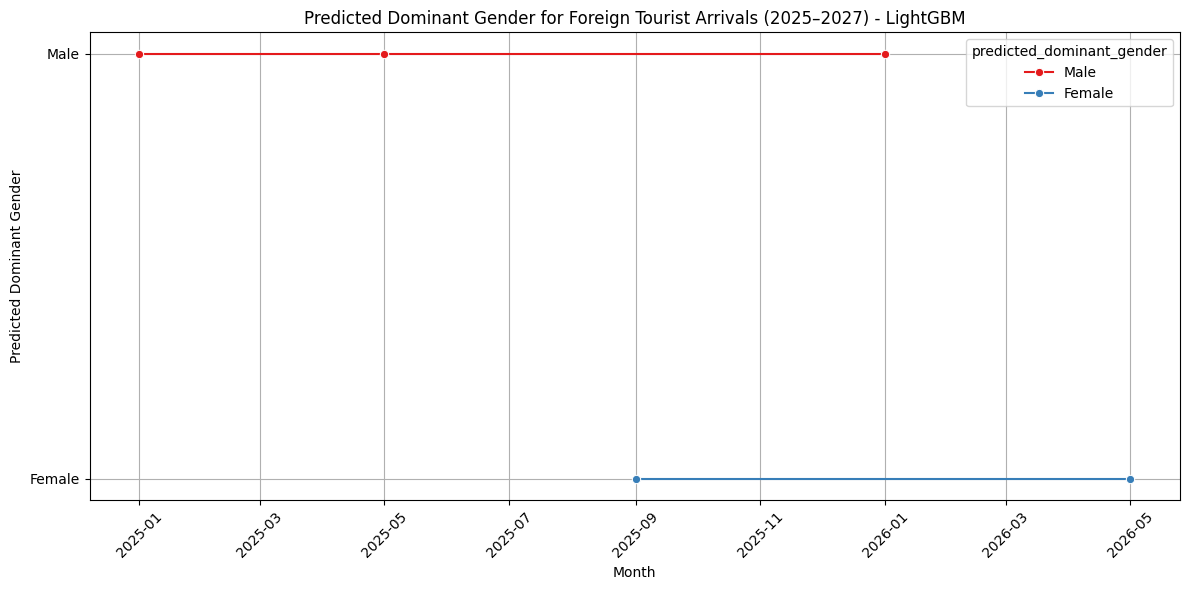

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
from datetime import datetime

# Create a mock dataset with month and predicted dominant gender
data = {
    'month_year': ['2025-01', '2025-05', '2025-09', '2026-01', '2026-05'],  # Sample months
    'predicted_dominant_gender': ['Male', 'Male', 'Female', 'Male', 'Female']  # Sample predictions
}
df_predict_binary = pd.DataFrame(data)  # Create a DataFrame from the dictionary

# Convert 'month_year' to datetime format for proper time-series plotting
df_predict_binary['month_year'] = pd.to_datetime(df_predict_binary['month_year'])

# Sort the DataFrame by time in ascending order
df_predict_binary = df_predict_binary.sort_values('month_year')

# Plot only if the DataFrame is not empty
if not df_predict_binary.empty:
    plt.figure(figsize=(12, 6))  # Set plot size
    sns.lineplot(
        data=df_predict_binary,             # Use the prediction data
        x='month_year',                     # X-axis: month
        y='predicted_dominant_gender',      # Y-axis: gender category
        hue='predicted_dominant_gender',    # Color by gender
        palette='Set1',                     # Use a predefined color set
        marker='o',                         # Add markers at each point
        legend=True                         # Show legend
    )
    plt.title('Predicted Dominant Gender for Foreign Tourist Arrivals (2025–2027) - LightGBM')
    plt.xlabel('Month')                     # X-axis label
    plt.ylabel('Predicted Dominant Gender') # Y-axis label
    plt.xticks(rotation=45)                 # Rotate x-axis labels for readability
    plt.grid(True)                          # Show gridlines
    plt.tight_layout()                      # Auto-adjust layout
    plt.show()                              # Display the plot
else:
    print("Prediction DataFrame is empty. Cannot generate plot.")  # Error message if no data

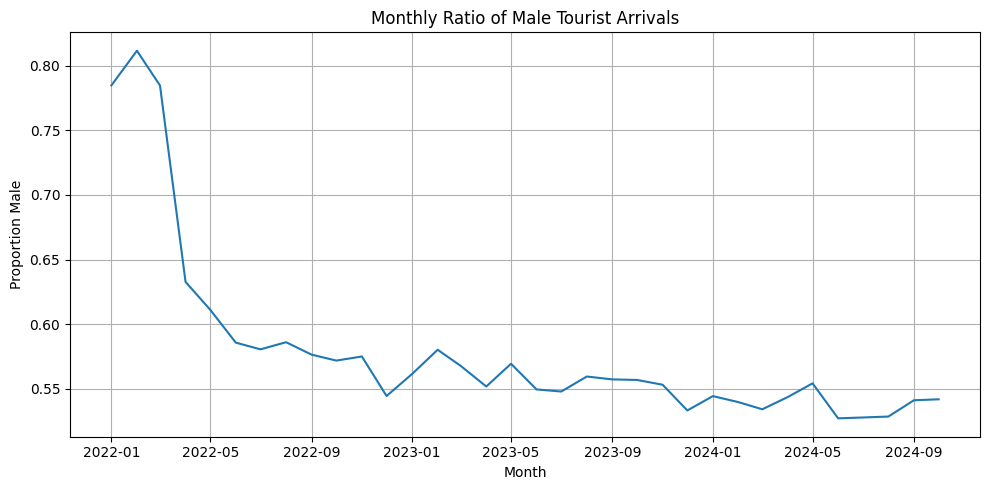

In [ ]:
# Group original data by month and sum male and female arrivals
df_gender_trend = df_edited.groupby('month_year')[['arrivals_male', 'arrivals_female']].sum()

# Calculate the male ratio = male / (male + female)
df_gender_trend['male_ratio'] = df_gender_trend['arrivals_male'] / (
    df_gender_trend['arrivals_male'] + df_gender_trend['arrivals_female']
)

# Plot the trend of male ratio over time
plt.figure(figsize=(10, 5))  # Set plot size
plt.plot(df_gender_trend.index, df_gender_trend['male_ratio'], label='Male Ratio')  # Plot line
plt.title('Monthly Ratio of Male Tourist Arrivals')  # Title
plt.xlabel('Month')  # X-axis label
plt.ylabel('Proportion Male')  # Y-axis label
plt.grid(True)  # Show gridlines
plt.tight_layout()  # Prevent overlapping
plt.show()  # Display plot

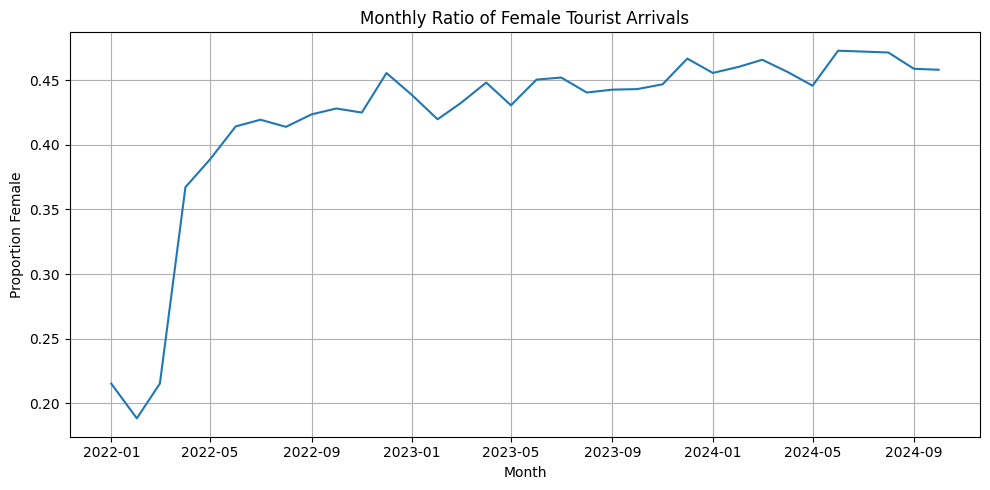

In [ ]:
# Group again (in case the previous one is overwritten) by month and sum gender arrivals
df_gender_trend = df_edited.groupby('month_year')[['arrivals_male', 'arrivals_female']].sum()

# Calculate the female ratio = female / (male + female)
df_gender_trend['female_ratio'] = df_gender_trend['arrivals_female'] / (
    df_gender_trend['arrivals_male'] + df_gender_trend['arrivals_female']
)

# Plot the trend of female ratio over time
plt.figure(figsize=(10, 5))  # Set plot size
plt.plot(df_gender_trend.index, df_gender_trend['female_ratio'], label='Female Ratio')  # Plot line
plt.title('Monthly Ratio of Female Tourist Arrivals')  # Title
plt.xlabel('Month')  # X-axis label
plt.ylabel('Proportion Female')  # Y-axis label
plt.grid(True)  # Show gridlines
plt.tight_layout()  # Prevent overlap
plt.show()  # Display plot

Saving results to CSV files

In [ ]:
import pandas as pd
# These include:
# - df_edited (the main dataframe after initial loading and filtering)
# - monthly_data (aggregated monthly data for total arrivals)
# - future_df (dataframe for future dates and features used in forecasting total arrivals)
# - country_predictions (dictionary of dataframes, one for each top country's predictions)
# - evaluation_df (dataframe summarizing country-specific model evaluation metrics)
# - df_predict_binary (dataframe for gender predictions)

# --- Save results to CSV files ---

# 1. Save the cleaned and filtered dataframe
df_edited.to_csv('/content/drive/My Drive/df_edited.csv', index=False)
print("Saved df_edited.csv to Google Drive")

# 2. Save the aggregated monthly data for total arrivals
monthly_data.to_csv('/content/drive/My Drive/monthly_data.csv', index=False)
print("Saved monthly_data.csv to Google Drive")

# 3. Save the future forecast data for total arrivals (XGBoost/Random Forest)
# Assuming future_df also contains the predicted values from either model (e.g., y_future or y_future_rf)
# We need to make sure future_df includes the prediction column(s) before saving.
# For demonstration, let's add the XGBoost predictions assuming they were stored in `y_future`
# and the Random Forest predictions in `y_future_rf`.
# If you only used one model, adjust accordingly.

# Assuming y_future (XGBoost forecast) is available
future_df_with_xgb_pred = future_df.copy()
future_df_with_xgb_pred['predicted_arrivals_xgb'] = y_future
future_df_with_xgb_pred.to_csv('/content/drive/My Drive/future_forecast_xgb.csv', index=False)
print("Saved future_forecast_xgb.csv to Google Drive")

# Assuming y_future_rf (Random Forest forecast) is available
future_df_with_rf_pred = future_df.copy() # Reuse the base future_df structure
future_df_with_rf_pred['predicted_arrivals_rf'] = y_future_rf
future_df_with_rf_pred.to_csv('/content/drive/My Drive/future_forecast_rf.csv', index=False)
print("Saved future_forecast_rf.csv to Google Drive")


# 4. Save the individual country predictions
# Iterate through the dictionary and save each country's prediction dataframe
for country, predictions_df in country_predictions.items():
    filename = f'/content/drive/My Drive/predictions_{country.replace(" ", "_")}.csv'
    predictions_df.to_csv(filename, index=False)
    print(f"Saved {filename} to Google Drive")

# 5. Save the country evaluation metrics
evaluation_df.to_csv('/content/drive/My Drive/country_evaluation_metrics.csv') # index=True to keep country names
print("Saved country_evaluation_metrics.csv to Google Drive")

# 6. Save the gender prediction data
df_predict_binary.to_csv('/content/drive/My Drive/gender_predictions.csv', index=False)
print("Saved gender_predictions.csv to Google Drive")

# Note: Feature importance plots and other visualizations are outputs, not dataframes
# that can be easily saved as CSVs. If you need the raw importance scores, you can
# create a small dataframe and save it.

# Example: Save XGBoost feature importance scores
xgb_importance_df = pd.DataFrame({
    'feature': features_xgb,
    'importance_score': importances_xgb
})
xgb_importance_df.to_csv('/content/drive/My Drive/xgb_feature_importance.csv', index=False)
print("Saved xgb_feature_importance.csv to Google Drive")

# Example: Save Random Forest feature importance scores
rf_importance_df = pd.DataFrame({
    'feature': features_rf,
    'importance_score': importances_rf
})
rf_importance_df.to_csv('/content/drive/My Drive/rf_feature_importance.csv', index=False)
print("Saved rf_feature_importance.csv to Google Drive")

df_country_monthly.to_csv('/content/drive/My Drive/df_country_monthly.csv', index=False)
print("Saved df_country_monthly.csv to Google Drive")

Saved df_edited.csv to Google Drive
Saved monthly_data.csv to Google Drive
Saved future_forecast_xgb.csv to Google Drive
Saved future_forecast_rf.csv to Google Drive
Saved /content/drive/My Drive/predictions_SGP.csv to Google Drive
Saved /content/drive/My Drive/predictions_IDN.csv to Google Drive
Saved /content/drive/My Drive/predictions_THA.csv to Google Drive
Saved /content/drive/My Drive/predictions_CHN.csv to Google Drive
Saved /content/drive/My Drive/predictions_BRN.csv to Google Drive
Saved /content/drive/My Drive/predictions_IND.csv to Google Drive
Saved /content/drive/My Drive/predictions_PHL.csv to Google Drive
Saved /content/drive/My Drive/predictions_BGD.csv to Google Drive
Saved /content/drive/My Drive/predictions_KOR.csv to Google Drive
Saved /content/drive/My Drive/predictions_VNM.csv to Google Drive
Saved country_evaluation_metrics.csv to Google Drive
Saved gender_predictions.csv to Google Drive
Saved xgb_feature_importance.csv to Google Drive
Saved rf_feature_importance